In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import numpy as np
from numpy.typing import NDArray
from sklearn.metrics import (
    explained_variance_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [36]:
def evaluate_regression_models(
    predictions: dict[str, NDArray[np.float64]], y: NDArray[np.float64]
) -> pd.DataFrame:
    """Evaluate multiple regression model predictions on the given dataset.

    Args:
        predictions (dict[str, NDArray[np.float64]]): Dictionary where keys are
            model names and values are predicted target arrays corresponding to X.
        y (NDArray[np.float64]): True target values of shape (n_samples,).

    Returns:
        pd.DataFrame: DataFrame with evaluation metrics (MAE, MSE, RMSE, R², EVS) for
            each model. Columns correspond to model names; rows correspond to metrics.
    """
    evaluations = pd.DataFrame(
        columns=predictions.keys(), index=["MAE", "MSE", "RMSE", "R²", "EVS"]
    )

    for name, y_pred in predictions.items():
        metrics = {
            "MAE": mean_absolute_error(y, y_pred),
            "MSE": mean_squared_error(y, y_pred),
            "RMSE": root_mean_squared_error(y, y_pred),
            "R²": r2_score(y, y_pred),
            "EVS": explained_variance_score(y, y_pred),
        }

        evaluations.loc[:, name] = metrics

    return evaluations.astype(float)

In [37]:
url = "https://statisticsglobe.com/wp-content/uploads/2023/09/data_pca_200x16.csv"
df = pd.read_csv(url, sep=";", decimal=",")

df.head()

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,x14,x15,y
0,-4.44,0.99,2.92,3.24,10.02,2.65,-2.10,-1.76,-3.24,6.95,-1.08,-2.11,-4.92,-13.50,-3.09,-0.47
1,13.92,1.51,2.93,3.81,-3.15,2.20,-5.39,1.84,-2.70,-0.39,0.02,5.01,-2.22,-0.55,-0.98,0.99
2,4.57,0.48,-0.62,4.52,1.41,1.35,4.95,1.51,4.12,-1.10,0.46,-0.85,2.38,-5.09,0.70,1.36
3,6.58,1.48,-0.90,1.74,0.79,1.98,4.10,0.93,0.71,-2.11,-1.80,5.43,2.15,-0.24,0.57,1.43
4,1.78,2.84,3.61,0.05,-0.33,2.49,0.72,1.28,2.06,3.86,0.57,3.33,-1.26,0.64,-6.14,1.03


In [38]:
y = df["y"]
X = df[['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'x10', 'x11', 'x12', 'x13', 'x14', 'x15']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X.astype(float))

In [39]:
pca = PCA().fit(X)

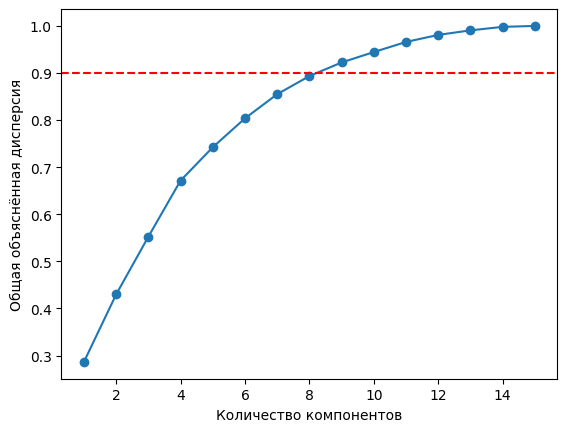

In [40]:
plt.plot(range(1, X.shape[1]+1), pca.explained_variance_ratio_.cumsum(), marker="o")
plt.xlabel("Количество компонентов")
plt.ylabel("Общая объяснённая дисперсия")
plt.axhline(0.9, color="red", linestyle="--")
plt.show()

In [41]:
k = (pca.explained_variance_ratio_.cumsum() < 0.9).sum() + 1
print(f"Нужно {k} компонент(ы), чтобы объяснить 90% дисперсии")

Нужно 9 компонент(ы), чтобы объяснить 90% дисперсии


In [42]:
pca = PCA(n_components=k)
X_pca = pca.fit_transform(X_scaled)

In [43]:
X_train, X_val, y_train, y_val = train_test_split(X_pca, y, test_size=0.2, random_state=42)
clf = LinearRegression()
clf.fit(X_train, y_train)
y_pred = clf.predict(X_val)

In [45]:
evaluate_regression_models({"pca+lin": y_pred}, y_val).T

,MAE,MSE,RMSE,R²,EVS
pca+lin,0.267025,0.12732,0.356819,0.56795,0.567964
